# Econ 372 — Homework 3

Damir Penaranda

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the hospital dataset
df = pd.read_csv("../data/hospital-panel.csv")

# Keep only the years required by the assignment
df = df[df["year"].between(1998, 2017)].copy()

# Preview the dataset
print(df.head())
print(df.shape)
print(df.columns.tolist())


   provider_number                  street    city state      zip  beds  \
0            10001  1108 ROSS CLARK CIRCLE  DOTHAN    AL  36301.0   425   
1            10001  1108 ROSS CLARK CIRCLE  DOTHAN    AL  36301.0   400   
2            10001  1108 ROSS CLARK CIRCLE  DOTHAN    AL  36301.0   353   
3            10001  1108 ROSS CLARK CIRCLE  DOTHAN    AL  36301.0   353   
4            10001  1108 ROSS CLARK CIRCLE  DOTHAN    AL  36301.0   353   

   tot_discharges        price  year  hrr   mkt  
0         16812.0  5298.301254  1998  2.0  11.0  
1         17876.0  3903.631715  1999  2.0  11.0  
2         17202.0  3902.972237  2000  2.0  11.0  
3         19477.0  3211.728081  2001  2.0  11.0  
4         19881.0  4255.351889  2002  2.0  11.0  
(55821, 11)
['provider_number', 'street', 'city', 'state', 'zip', 'beds', 'tot_discharges', 'price', 'year', 'hrr', 'mkt']


## Question 1

Q1.a:





In [10]:
# Function to calculate HHI by market and year
def calculate_hhi(data, market_col):
    d = data.dropna(subset=[market_col]).copy()

    # Total discharges within each market-year
    d["market_discharges"] = (
        d.groupby(["year", market_col])["tot_discharges"]
        .transform("sum")
    )

    # Calculate each hospital's market share
    d["share"] = d["tot_discharges"] / d["market_discharges"]

    # Calculate each hospital's contribution to HHI
    d["hhi_component"] = 10000 * d["share"]**2

    # Aggregate to the market-year level
    result = d.groupby(["year", market_col], as_index=False).agg(
        hhi=("hhi_component", "sum"),
        max_share=("share", "max"),
        n_hospitals=("provider_number", "nunique"),
        market_discharges=("tot_discharges", "sum")
    )

    return result, d

# Calculate HHI using all three market definitions
zip_hhi, zip_detail = calculate_hhi(df, "zip")
hrr_hhi, hrr_detail = calculate_hhi(df, "hrr")
mkt_hhi, mkt_detail = calculate_hhi(df, "mkt")

# Average HHI in each year
avg_hhi = pd.DataFrame({
    "ZIP": zip_hhi.groupby("year")["hhi"].mean(),
    "HRR": hrr_hhi.groupby("year")["hhi"].mean(),
    "Community": mkt_hhi.groupby("year")["hhi"].mean()
})

print(avg_hhi.round(2))

          ZIP      HRR  Community
year                             
1998  9802.88  4237.51    6005.76
1999  9728.68  2905.94    5282.46
2000  9732.21  2977.65    5232.10
2001  9733.68  2945.59    5326.11
2002  9743.49  3017.88    5339.68
2003  9751.50  3074.31    5309.76
2004  9750.46  3059.66    5425.99
2005  9724.46  3083.73    5364.54
2006  9728.11  3064.88    5415.39
2007  9727.64  3040.05    5372.87
2008  9750.68  3115.37    5392.63
2009  9756.38  3114.34    5458.14
2010  9753.56  3189.97    5533.50
2011  9749.46  3199.17    5531.78
2012  9763.19  3232.26    5485.81
2013  9762.34  3333.59    5544.32
2014  9767.67  3302.91    5476.56
2015  9758.68  3302.82    5549.35
2016  9758.63  3330.25    5470.87
2017  9765.60  3361.71    5516.82


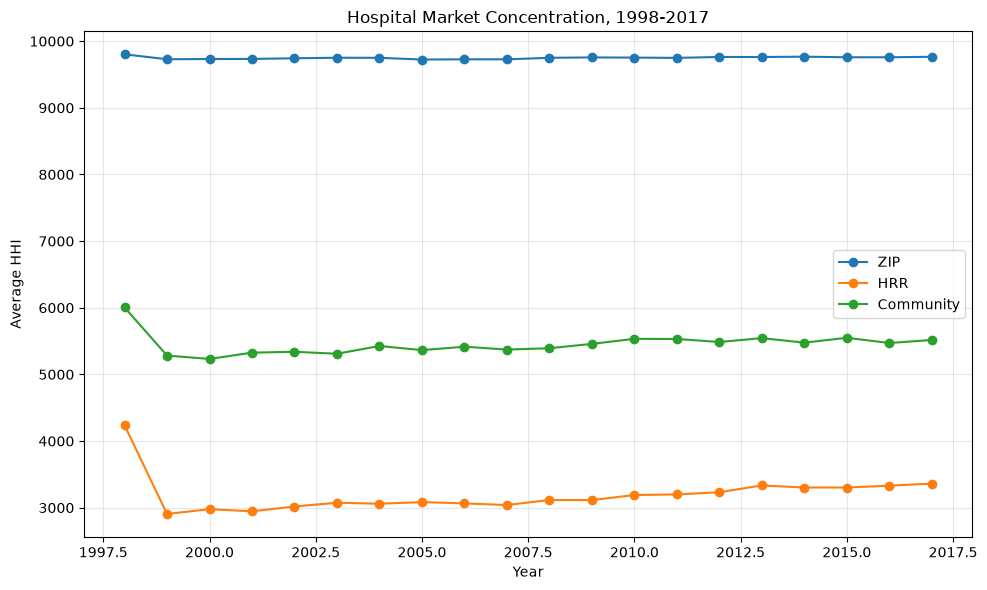

In [11]:

plt.figure(figsize=(10, 6))

for col in avg_hhi.columns:
    plt.plot(avg_hhi.index, avg_hhi[col],
             marker="o", label=col)

plt.xlabel("Year")
plt.ylabel("Average HHI")
plt.title("Hospital Market Concentration, 1998-2017")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


From this analysis we see that average HHI varies substantially depending on how hospital markets are defined. ZIP-code markets have the highest concentration, with average HHI remaining near 9,800 throughout the period. Meanwhile, community-detection markets show lower concentration, declining from approximately 6,006 in 1998 to 5,517 in 2017, while HRR markets have the lowest HHI, declining from 4,238 to 3,362. Overall, this data suggests that concentration generally decreased between 1998 and 2017, particularly under the broader market definitions.

## Question 1b

Market definition changes the concentration measure because it determines which hospitals are considered competitors. ZIP codes are narrow geographic areas, so many markets contain only one hospital, resulting in an HHI of 10,000. HRRs include more hospitals and therefore generally produce lower concentration, while community-detection markets fall between the two. There is no single correct definition because patients may travel different distances depending on the care they need. The most appropriate market should reflect which hospitals patients realistically consider substitutes.

## Question 1c


In [12]:

# Compare different methods of averaging HHI
def compare_hhi(data):
    results = []

    for year, group in data.groupby("year"):
        unweighted = group["hhi"].mean()

        weighted = np.average(
            group["hhi"],
            weights=group["market_discharges"]
        )

        no_single = group.loc[
            group["n_hospitals"] > 1, "hhi"
        ].mean()

        results.append({
            "year": year,
            "Unweighted": unweighted,
            "Weighted": weighted,
            "No single-hospital markets": no_single
        })

    return pd.DataFrame(results).set_index("year")

zip_comparison = compare_hhi(zip_hhi)
hrr_comparison = compare_hhi(hrr_hhi)
mkt_comparison = compare_hhi(mkt_hhi)

print("ZIP:")
print(zip_comparison.round(2))

print("\nHRR:")
print(hrr_comparison.round(2))

print("\nCommunity:")
print(mkt_comparison.round(2))


ZIP:
      Unweighted  Weighted  No single-hospital markets
year                                                  
1998     9802.88   9429.01                     5875.97
1999     9728.68   9238.80                     5837.46
2000     9732.21   9535.07                     5797.02
2001     9733.68   9264.90                     5797.05
2002     9743.49   9278.89                     5794.96
2003     9751.50   9317.45                     5681.37
2004     9750.46   9270.16                     5725.64
2005     9724.46   9249.31                     5729.10
2006     9728.11   9264.77                     5735.54
2007     9727.64   9248.52                     5764.77
2008     9750.68   9298.77                     5835.09
2009     9756.38   9323.14                     5762.93
2010     9753.56   9323.12                     5761.16
2011     9749.46   9313.55                     5747.61
2012     9763.19   9334.72                     5881.38
2013     9762.34   9335.40                     5785.25
2014 

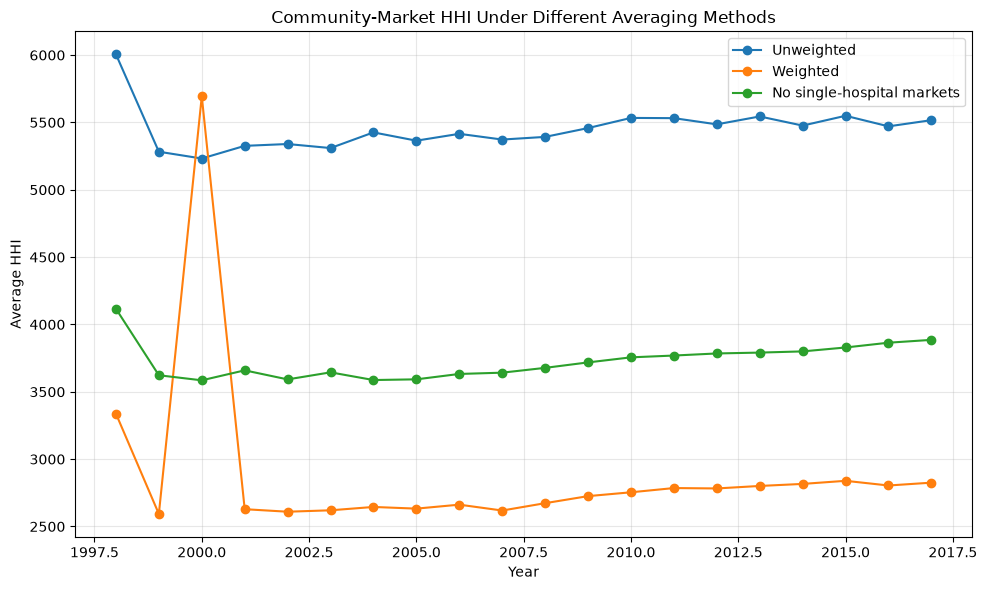

In [13]:

plt.figure(figsize=(10, 6))

for col in mkt_comparison.columns:
    plt.plot(
        mkt_comparison.index,
        mkt_comparison[col],
        marker="o",
        label=col
    )

plt.xlabel("Year")
plt.ylabel("Average HHI")
plt.title("Community-Market HHI Under Different Averaging Methods")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The simple average gives small markets the same weight as much larger ones, which can make overall concentration appear higher than what most patients actually experience. In community-detection markets, the 2017 average HHI falls from 5,517 to 2,825 when weighted by discharges, and to 3,886 when single-hospital markets are excluded. This happens because small markets with only one hospital automatically have an HHI of 10,000 and pull up the unweighted average. Weighting by discharges provides a better picture of concentration across hospital discharges, while the original average primarily describes the typical market regardless of its size. The original average fails to account for differences in market size and patient volume, meaning it reflects the concentration of the typical market rather than the competitive conditions faced by the typical patient.

## Question 1d

In [14]:

# Q1(d): Check that market shares sum to 1

for name, detail, market_col in [
    ("ZIP", zip_detail, "zip"),
    ("HRR", hrr_detail, "hrr"),
    ("Community", mkt_detail, "mkt")
]:

    # Sum hospital market shares within each market-year
    share_sums = detail.groupby(
        ["year", market_col]
    )["share"].sum()

    # Check whether all market-year totals equal 1
    valid = np.allclose(share_sums, 1.0)

    print(name, "markets")
    print("Minimum share sum:", round(share_sums.min(), 6))
    print("Maximum share sum:", round(share_sums.max(), 6))
    print("All shares sum to 1:", valid)
    print()


ZIP markets
Minimum share sum: 1.0
Maximum share sum: 1.0
All shares sum to 1: True

HRR markets
Minimum share sum: 1.0
Maximum share sum: 1.0
All shares sum to 1: True

Community markets
Minimum share sum: 1.0
Maximum share sum: 1.0
All shares sum to 1: True



In [15]:

# Additional consistency checks for Q1(d)

# Check 1: Each hospital should appear once per year
duplicates = df.duplicated(
    subset=["provider_number", "year"]
).sum()

print("Duplicate hospital-year observations:", duplicates)

# Check 2: HHI must be between 0 and 10,000
for name, data in [
    ("ZIP", zip_hhi),
    ("HRR", hrr_hhi),
    ("Community", mkt_hhi)
]:
    valid_hhi = data["hhi"].between(0, 10000).all()

    # Single-hospital markets should have HHI = 10,000
    monopoly_hhi = data.loc[
        data["n_hospitals"] == 1, "hhi"
    ]

    valid_monopolies = np.allclose(monopoly_hhi, 10000)

    print(name)
    print("HHI within valid range:", valid_hhi)
    print("Single-hospital HHI equals 10,000:", valid_monopolies)
    print()


Duplicate hospital-year observations: 0
ZIP
HHI within valid range: True
Single-hospital HHI equals 10,000: True

HRR
HHI within valid range: True
Single-hospital HHI equals 10,000: True

Community
HHI within valid range: True
Single-hospital HHI equals 10,000: True



I checked that hospital market shares sum to 1 within each market-year for all three definitions, and ensured they all passed. This test confirms that the calculated shares are consistent with their market discharge totals. If hospitals were matched to incorrect market totals through a careless join, their shares could sum to more or less than 1, causing HHI to be overstated or understated. Since HHI is calculated using squared market shares, incorrect denominators would distort the concentration measure. However, this check alone cannot identify every possible mistake, since incorrect hospital assignments could still produce shares that sum to 1 if the market totals were recalculated consistently. So, I also added checks for duplicate hospital-year observations, whether HHI falls within its valid range of 0 to 10,000, and whether single-hospital markets have an HHI of exactly 10,000. This helps provide an additional way to identify potential errors in the data or calculations. 

## Question 1e

In [16]:

# Q1(e): Average maximum market share by year

avg_max = pd.DataFrame({
    "ZIP": zip_hhi.groupby("year")["max_share"].mean(),
    "HRR": hrr_hhi.groupby("year")["max_share"].mean(),
    "Community": mkt_hhi.groupby("year")["max_share"].mean()
})

# Convert shares to percentages
avg_max = avg_max * 100

print(avg_max.round(2))


        ZIP    HRR  Community
year                         
1998  98.43  53.08      67.58
1999  97.87  40.51      61.01
2000  97.88  41.13      60.35
2001  97.89  40.79      61.28
2002  97.97  41.28      61.20
2003  98.03  41.85      61.10
2004  98.03  41.77      62.00
2005  97.82  41.97      61.49
2006  97.85  41.76      62.03
2007  97.84  41.60      61.66
2008  98.02  42.52      61.84
2009  98.06  42.34      62.47
2010  98.07  42.90      63.14
2011  98.03  42.96      63.21
2012  98.16  43.28      62.88
2013  98.14  44.42      63.31
2014  98.18  43.90      62.71
2015  98.12  44.07      63.50
2016  98.13  44.34      62.88
2017  98.18  44.59      63.17


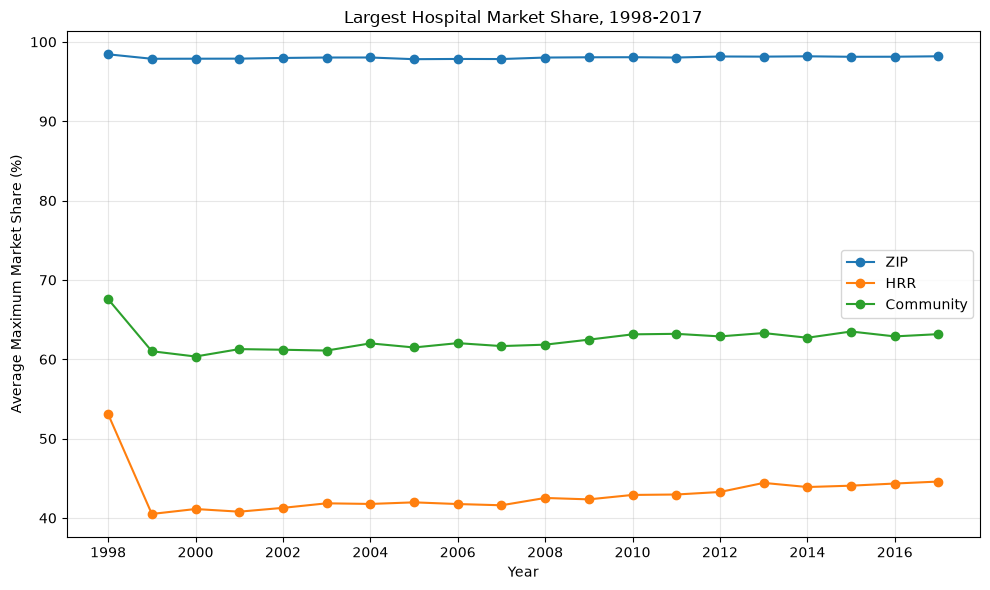

In [18]:

# Plot maximum market share over time
plt.figure(figsize=(10, 6))

for col in avg_max.columns:
    plt.plot(
        avg_max.index,
        avg_max[col],
        marker="o",
        label=col
    )

plt.xlabel("Year")
plt.ylabel("Average Maximum Market Share (%)")
plt.title("Largest Hospital Market Share, 1998-2017")
plt.xticks(range(1998, 2018, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Using the largest hospital's market share produces a similar assessment of competitiveness to HHI. ZIP-code markets remain the most concentrated, with the largest hospital accounting for approximately 98.18% of discharges in 2017, compared with 63.17% in community markets and 44.59% in HRRs. Maximum shares also decline between 1998 and 2017 across all three definitions, suggesting that hospital dominance generally decreased over time. The contrast with HHI shows that while both measures identify similar patterns, they capture different aspects of competition. Maximum share only measures the dominance of the largest hospital, whereas HHI accounts for the distribution of market shares across all hospitals. For instance, two markets could have the same largest-hospital share but different HHI values if the remaining discharges are distributed differently among smaller competitors. Thus, examining the contrast in HHI provides a more complete measure of overall market concentration, while maximum share is useful for identifying the dominance of individual hospitals.

Question 2a

Average hospital price by year:
year
1998     5100.69
1999     5240.72
2000     5537.22
2001     5854.40
2002     6334.26
2003     6858.11
2004     7216.74
2005     7561.94
2006     7979.20
2007     8343.12
2008     8764.01
2009     9048.69
2010     9339.79
2011     9670.63
2012     9646.94
2013     9606.08
2014    10019.15
2015    10450.19
2016    10438.18
2017    10600.97
Name: price, dtype: float64


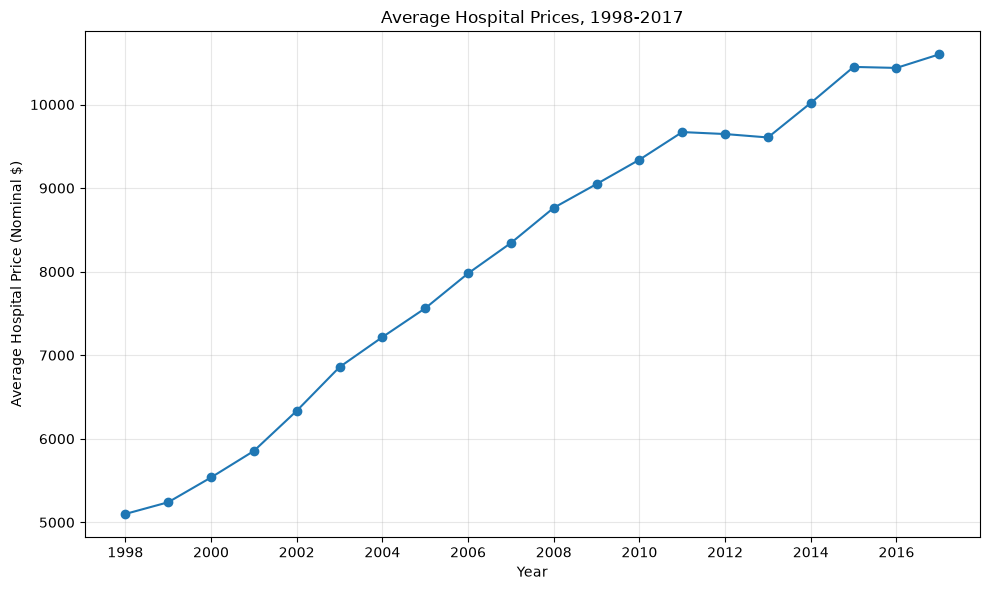

In [19]:

# Q2(a): Calculate average hospital price by year
avg_price = df.groupby("year")["price"].mean()

print("Average hospital price by year:")
print(avg_price.round(2))

# Plot average prices over time
plt.figure(figsize=(10, 6))

plt.plot(
    avg_price.index,
    avg_price.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Average Hospital Price (Nominal $)")
plt.title("Average Hospital Prices, 1998-2017")
plt.xticks(range(1998, 2018, 2))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

# Examine the distribution of constructed prices
price_stats = df["price"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

print("Price distribution:")
print(price_stats.round(2))

# Additional data-quality checks
print("\nMissing prices:", df["price"].isna().sum())
print("Nonpositive prices:", (df["price"] <= 0).sum())

# Percentage change from 1998 to 2017
price_growth = (
    (avg_price.loc[2017] / avg_price.loc[1998]) - 1
) * 100

print("Nominal price growth:", round(price_growth, 2), "%")


Price distribution:
count    55821.00
mean      8128.74
std       5074.57
min          1.95
1%        1264.01
25%       4811.21
50%       7111.68
75%      10186.02
99%      25817.84
max      97688.81
Name: price, dtype: float64

Missing prices: 0
Nonpositive prices: 0
Nominal price growth: 107.83 %


The average constructed hospital price increased from \$5,100.69 in 1998 to \$10,600.97 in 2017, representing an increase of approximately 108%. The distribution shows considerable variation across hospitals, with prices ranging from \$1.95 to \$97,688.81, a median of \$7,111.68, and a mean of \$8,128.74. Since the mean exceeds the median and the maximum is unusually high, the distribution appears right-skewed, suggesting that some outliers heavily influence the average.

However, this measure is not a hospital's sticker price or the negotiated payment for a particular service. It is constructed using adjusted charges net of Medicare payments, divided by non-Medicare discharges, making it an aggregate measure rather than a standardized price for identical treatment. As a result, differences in patient complexity, the services hospitals provide, and hospital accounting practices may affect the measure independently of actual pricing decisions. Additionally, the values are expressed in unajusted, nominal dollars, meaning inflation contributes to the observed increase. Therefore, while the graph shows a substantial upward trend, it does not necessarily mean that hospitals increased their real prices for comparable services by the same amount.

Question 2b

In [21]:

# Q2(b): Classify community markets by hospital count
market_structure = mkt_hhi.copy()

market_structure["structure"] = np.select(
    [
        market_structure["n_hospitals"] == 1,
        market_structure["n_hospitals"] == 2,
        market_structure["n_hospitals"] >= 4
    ],
    [
        "Monopoly",
        "Duopoly",
        "Competitive"
    ],
    default="Three hospitals"
)

# Count each market type in every year
market_counts = (
    market_structure.groupby(["year", "structure"])
    .size()
    .unstack(fill_value=0)
)

print(market_counts)


structure  Competitive  Duopoly  Monopoly  Three hospitals
year                                                      
1998               158       93       149               64
1999               248      103       146               64
2000               244       99       143               71
2001               243      102       148               70
2002               242       97       153               69
2003               245      101       147               68
2004               241       90       162               72
2005               241       91       151               63
2006               240       96       154               60
2007               240      104       150               57
2008               238      105       150               60
2009               236      105       154               61
2010               235      109       160               58
2011               229      100       157               69
2012               235      108       153               

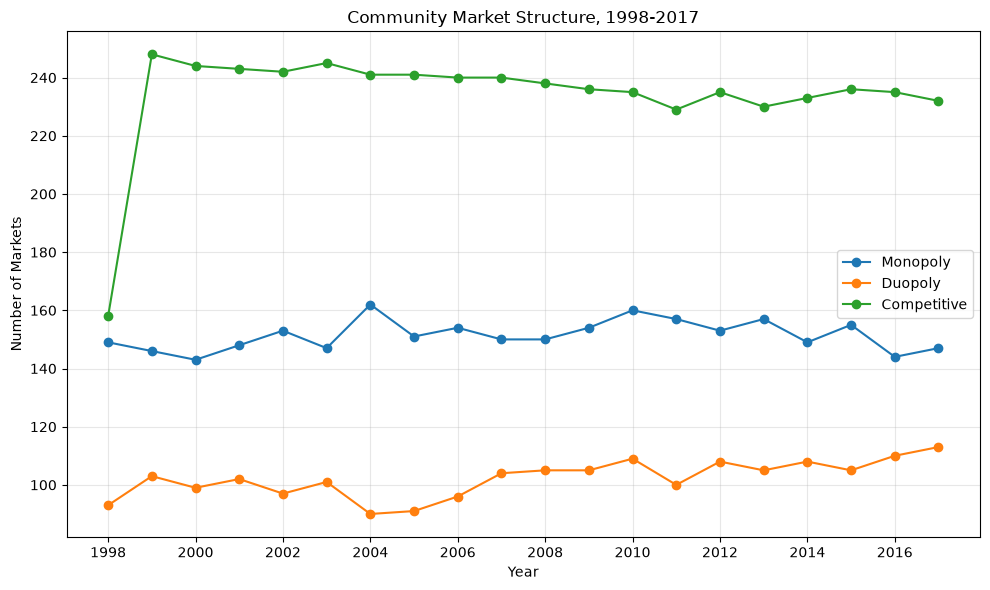

In [22]:

# Plot the number of market-years by structure
plt.figure(figsize=(10, 6))

for group in ["Monopoly", "Duopoly", "Competitive"]:
    plt.plot(
        market_counts.index,
        market_counts[group],
        marker="o",
        label=group
    )

plt.xlabel("Year")
plt.ylabel("Number of Markets")
plt.title("Community Market Structure, 1998-2017")
plt.xticks(range(1998, 2018, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


This graph visualizes community-detection market-years according to the number of hospitals operating within each market. Markets with exactly one hospital are considered monopolies, those with two hospitals are duopolies, and markets with at least four hospitals are classified as competitive. Markets containing exactly three hospitals are excluded from these categories. Between 1998 and 2017, the number of competitive markets increased from 158 to 232, while duopolies increased from 93 to 113. Monopolies remained relatively stable, decreasing slightly from 149 to 147.

The largest change was the growth in markets containing at least four hospitals, which increased by approximately 47%. This suggests that a greater number of observed markets contained multiple potential competitors by the end of the period. However, counting hospitals does not fully capture competition because hospitals may differ in size, market share, or the services they provide. Additionally, changes in the number of observed markets do not necessarily mean that individual markets became more competitive, since the composition of the dataset may also change over time. I am also left wondering about those markets in which there are exactly 3 hospitals.

## Question 2c

In [1]:

# Q2(c): Match hospitals with their market classification
hospital_prices = df.merge(
    market_structure[
        ["year", "mkt", "structure", "market_discharges"]
    ],
    on=["year", "mkt"],
    how="inner",
    validate="many_to_one"
)

# Combine monopolies and duopolies
hospital_prices["market_group"] = np.select(
    [
        hospital_prices["structure"].isin(
            ["Monopoly", "Duopoly"]
        ),
        hospital_prices["structure"] == "Competitive"
    ],
    [
        "Monopoly/Duopoly",
        "Competitive"
    ],
    default="Other"
)

# Exclude three-hospital markets
price_sample = hospital_prices[
    hospital_prices["market_group"] != "Other"
].copy()

# Calculate average prices by group and year
price_comparison = (
    price_sample.groupby(["year", "market_group"])["price"]
    .mean()
    .unstack()
)

print("Average price by market structure:")
print(price_comparison.round(2))


NameError: name 'df' is not defined

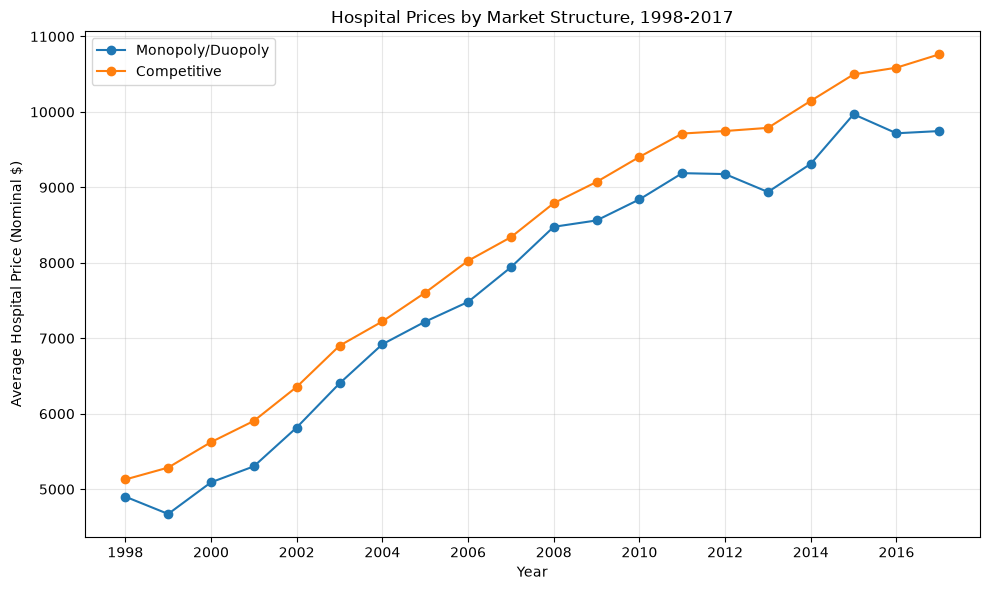

In [ ]:

# Compare prices between concentrated and competitive markets
plt.figure(figsize=(10, 6))

for group in ["Monopoly/Duopoly", "Competitive"]:
    plt.plot(
        price_comparison.index,
        price_comparison[group],
        marker="o",
        label=group
    )

plt.xlabel("Year")
plt.ylabel("Average Hospital Price (Nominal $)")
plt.title("Hospital Prices by Market Structure, 1998-2017")
plt.xticks(range(1998, 2018, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


This unadjusted comparison shows that hospitals located in competitive markets generally have higher average constructed prices than hospitals in monopoly or duopoly markets. In 2017, hospitals in competitive markets had an average price of \$10,763.57, compared with \$9,746.50 in concentrated markets, a difference of approximately \$1,017. This signals a negative relationship between market concentration and hospital prices in the raw data, meaning hospitals facing fewer competitors appear to have lower prices.

This finding contrasts with the traditional economic prediction that hospitals with greater market power may be able to negotiate higher prices because patients and insurers have fewer alternatives. However, the comparison does not account for differences between the markets themselves. Competitive markets are often larger and more urban, potentially containing hospitals that provide specialized treatments, face higher operating costs, or treat patients with more complex conditions. Since the constructed price variable also reflects differences in services and patient mix, these characteristics may explain why competitive markets appear more expensive. Therefore, the raw correlation does not necessarily imply that greater competition causes higher hospital prices and further factors must be considered.

Question 2d

In [ ]:

# Q2(d): Restrict to markets with 10,000-50,000 discharges
similar_size = price_sample[
    price_sample["market_discharges"].between(10000, 50000)
].copy()

# Calculate the new yearly average prices
size_comparison = (
    similar_size.groupby(["year", "market_group"])["price"]
    .mean()
    .unstack()
)

print("Prices in similarly sized markets:")
print(size_comparison.round(2))

# Check how many hospital observations remain
print("\nHospital observations by group:")
print(similar_size["market_group"].value_counts())


Prices in similarly sized markets:
market_group  Competitive  Monopoly/Duopoly
year                                       
1998              4811.53           5598.05
1999              4788.39           4983.39
2000              5156.24           5283.96
2001              5242.86           5485.87
2002              5738.97           6064.78
2003              6249.14           6506.76
2004              6518.69           7213.68
2005              7234.05           7596.06
2006              7260.15           7722.95
2007              7809.24           8491.53
2008              8148.24           8674.28
2009              8384.22           9053.90
2010              8705.20           9400.49
2011              8986.36           9976.78
2012              9012.65           9715.82
2013              9203.47           9670.73
2014              9555.23          10082.71
2015              9535.99          10512.60
2016              9695.61          10577.81
2017              9552.98          10622.

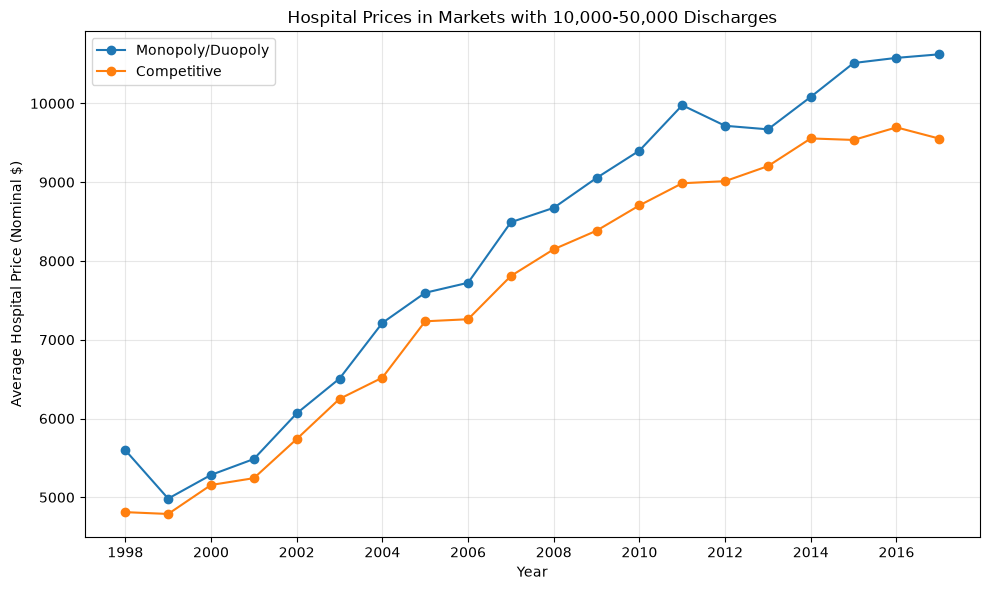

In [ ]:

# Plot prices after restricting market size
plt.figure(figsize=(10, 6))

for group in ["Monopoly/Duopoly", "Competitive"]:
    plt.plot(
        size_comparison.index,
        size_comparison[group],
        marker="o",
        label=group
    )

plt.xlabel("Year")
plt.ylabel("Average Hospital Price (Nominal $)")
plt.title("Hospital Prices in Markets with 10,000-50,000 Discharges")
plt.xticks(range(1998, 2018, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Price gap before restricting market size
raw_gap = (
    price_comparison["Monopoly/Duopoly"]
    - price_comparison["Competitive"]
)

# Price gap after restricting market size
restricted_gap = (
    size_comparison["Monopoly/Duopoly"]
    - size_comparison["Competitive"]
)

# Display both gaps by year
gap_comparison = pd.DataFrame({
    "Original Gap": raw_gap,
    "Restricted Gap": restricted_gap
})

print(gap_comparison.round(2))

# Compare the average annual gaps
print("\nAverage original gap:",
      round(raw_gap.mean(), 2))

print("Average restricted gap:",
      round(restricted_gap.mean(), 2))


      Original Gap  Restricted Gap
year                              
1998       -227.62          786.51
1999       -614.75          195.01
2000       -532.81          127.72
2001       -601.95          243.01
2002       -537.97          325.81
2003       -499.05          257.62
2004       -302.51          694.99
2005       -384.30          362.01
2006       -544.80          462.80
2007       -398.49          682.29
2008       -312.84          526.05
2009       -510.47          669.68
2010       -562.99          695.29
2011       -524.85          990.42
2012       -570.64          703.16
2013       -849.82          467.26
2014       -834.54          527.49
2015       -528.56          976.61
2016       -869.38          882.19
2017      -1017.07         1069.98

Average original gap: -561.27
Average restricted gap: 582.3


After restricting the sample to community-detection markets with between 10,000 and 50,000 annual discharges, the relationship between concentration and hospital prices reverses. In the unrestricted data, monopoly and duopoly hospitals generally had lower average prices than hospitals in competitive markets. However, among markets with similar discharge volumes, concentrated-market hospitals generally have higher prices. For example, in 2017, their average price was \$10,622.96, compared with \$9,552.98 in competitive markets, a difference of approximately \$1,070. Across the full period, the average annual price gap changes from −\$561 in the original sample to +\$582 after restricting market size.

This reversal suggests that market size was an important confounding factor in the original comparison. Concentrated markets tend to be smaller and more rural, while competitive markets are often larger and more urban. These differences may affect hospital prices through operating costs, patient characteristics, and the availability of specialized services, independently of competition. By restricting the sample to markets serving a similar number of patients, we reduce some of these differences and obtain a more meaningful comparison. The positive price relationship in the restricted sample is more consistent with the theory that hospitals facing fewer competitors may exercise greater market power. However, similar market size does not guarantee that hospitals are otherwise comparable, so the result remains correlational rather than causal.

Question 2e:

No, from our data the observed relationship between hospital concentration and prices does not provide sufficient evidence that concentration causes higher prices. The analysis shows that the direction of the correlation depends on which markets are compared. In the unrestricted sample, concentrated markets have lower average prices, but after limiting the comparison to similarly sized markets, they have higher prices. This reversal demonstrates how differences in market characteristics can influence the observed relationship. Although the restricted results are consistent with the theory that hospitals with fewer competitors may have greater pricing power, they do not establish that concentration itself caused the higher prices.

Other factors, including patient complexity, hospital quality, operating costs, and local demand, may influence both market structure and prices. There is also potential reverse causality, since hospital prices and profitability may affect decisions to enter, exit, or merge within a market. To make a stronger causal claim, we would need a research design that isolates changes in competition from these other influences. For instance, a difference-in-differences study could compare hospital prices before and after a merger with prices in similar markets that did not experience a merger. If those markets followed comparable trends beforehand and were not affected by other major changes, the analysis would provide stronger evidence of whether reduced competition actually causes hospital prices to increase and stronger support a causal relationship.